# 03b – Modelling and Evaluation

Classification of countries into three HDI-based categories (0 = Low, 1 = Medium/High, 2 = Very High) using the dataset `data/hdi_wdi_2023.csv` and the same stratified split and preprocessing as `03a_preprocessing.ipynb` (defined in the first code cell).

Preprocessing (chosen in `03a_preprocessing.ipynb`): mean imputation, no missingness indicators, signed-log transform of `inflation` and `trade_gdp`, standardisation of numerical features, one-hot encoding of `region` and `DominantSector` (missing values as a `Missing` category). All preprocessing is inside the pipeline and fitted on training data only. No PCA is used in the final models.

## 1. Data and split

In [1]:
# ---------- Setup: data, split and preprocessing (same in 03a and 03b) ----------
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

SEED = 42
CLASS_NAMES = ["Low", "Medium/High", "Very High"]
NUM = ["gdp_growth", "inflation", "unemployment", "infant_mortality", "electricity_access",
       "internet_users", "agriculture_gdp", "industry_gdp", "trade_gdp"]
CAT = ["region", "DominantSector"]
SKEWED = ["inflation", "trade_gdp"]          # heavily right-skewed (see EDA)

df = pd.read_csv("../data/hdi_wdi_2023.csv")

# Sign-preserving log for the two skewed features: sign(x) * log(1 + |x|).
# This is a fixed formula (nothing is learned from the data), so applying it before the split causes no leakage.
for c in SKEWED:
    df[c] = np.sign(df[c]) * np.log1p(np.abs(df[c]))

X = df[NUM + CAT]                  # predictors only: hdi, iso3 and country are never used as features
y = df["hdi_class"].to_numpy()

# Stratified 60 / 20 / 20 split: first 20% test, then 25% of the remaining 80% (= 20%) validation
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25,
                                                  stratify=y_trval, random_state=SEED)


def make_preprocessor(num=NUM, cat=CAT, impute="mean", indicator=False):
    """Imputation + scaling for numerical columns, "Missing" category + one-hot for categorical columns.
    It is only fitted inside a Pipeline on training data."""
    num = [c for c in num if c in SKEWED] + [c for c in num if c not in SKEWED]   # fixed column order
    transformers = []
    if num:
        transformers.append(("num", Pipeline([
            ("impute", SimpleImputer(strategy=impute, add_indicator=indicator)),
            ("scale", StandardScaler())]), num))
    if cat:
        transformers.append(("cat", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat))
    return ColumnTransformer(transformers)

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

# one stratified, shuffled 5-fold splitter used for every cross-validation step
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print("Train / validation / test:", len(X_train), len(X_val), len(X_test))
print("\nTraining set class counts:")
print(pd.Series(y_train).value_counts().sort_index())
print("\nValidation set class counts:")
print(pd.Series(y_val).value_counts().sort_index())
print("\nTest set class counts:")
print(pd.Series(y_test).value_counts().sort_index())

Train / validation / test: 115 39 39

Training set class counts:
0    16
1    55
2    44
Name: count, dtype: int64

Validation set class counts:
0     5
1    19
2    15
Name: count, dtype: int64

Test set class counts:
0     5
1    19
2    15
Name: count, dtype: int64


## 2. Model selection with stratified 5-fold cross-validation

All models are tuned on the training set only, using macro F1 as the selection metric. The same stratified, shuffled 5-fold splitter (`random_state = 42`) is used for every cross-validation step, so the folds are identical to those in `03a_preprocessing.ipynb`.

### 2.1 Majority-class baseline

In [2]:
majority_class = pd.Series(y_train).value_counts().index[0]
print("Majority class:", CLASS_NAMES[majority_class])

baseline_scores = []
for fold_idx, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train)):
    fold_majority = pd.Series(y_train[train_idx]).value_counts().index[0]
    fold_pred = np.array([fold_majority] * len(val_idx))
    baseline_scores.append(f1_score(y_train[val_idx], fold_pred, average="macro"))

print(f"Baseline CV macro F1: {np.mean(baseline_scores):.3f} ± {np.std(baseline_scores):.3f}")

Majority class: Medium/High
Baseline CV macro F1: 0.216 ± 0.000


### 2.2 Multinomial logistic regression

In [3]:
lr_pipeline = Pipeline([
    ("pre", make_preprocessor()),
    ("clf", LogisticRegression(max_iter=5000))
])
lr_param_grid = {"clf__C": [0.01, 0.1, 1, 10, 100]}

lr_search = GridSearchCV(lr_pipeline, lr_param_grid, cv=cv, scoring="f1_macro")
lr_search.fit(X_train, y_train)
print("Best parameters:", lr_search.best_params_)

best_C = lr_search.best_params_["clf__C"]
lr_model = Pipeline([
    ("pre", make_preprocessor()),
    ("clf", LogisticRegression(C=best_C, max_iter=5000))
])
lr_cv_scores = cross_val_score(lr_model, X_train, y_train, cv=cv, scoring="f1_macro")
print(f"CV macro F1: {lr_cv_scores.mean():.3f} ± {np.std(lr_cv_scores):.3f}")

Best parameters: {'clf__C': 100}


CV macro F1: 0.849 ± 0.094


### 2.3 Decision tree

In [4]:
dt_pipeline = Pipeline([
    ("pre", make_preprocessor()),
    ("clf", DecisionTreeClassifier(random_state=SEED))
])
dt_param_grid = {
    "clf__max_depth": [2, 3, 4, 5, None],
    "clf__min_samples_leaf": [1, 3, 5]
}

dt_search = GridSearchCV(dt_pipeline, dt_param_grid, cv=cv, scoring="f1_macro")
dt_search.fit(X_train, y_train)
print("Best parameters:", dt_search.best_params_)

best_dt_depth = dt_search.best_params_["clf__max_depth"]
best_dt_leaf = dt_search.best_params_["clf__min_samples_leaf"]
dt_model = Pipeline([
    ("pre", make_preprocessor()),
    ("clf", DecisionTreeClassifier(max_depth=best_dt_depth, min_samples_leaf=best_dt_leaf,
                                   random_state=SEED))
])
dt_cv_scores = cross_val_score(dt_model, X_train, y_train, cv=cv, scoring="f1_macro")
print(f"CV macro F1: {dt_cv_scores.mean():.3f} ± {np.std(dt_cv_scores):.3f}")

Best parameters: {'clf__max_depth': 4, 'clf__min_samples_leaf': 3}


CV macro F1: 0.801 ± 0.071


### 2.4 Random forest

In [5]:
rf_pipeline = Pipeline([
    ("pre", make_preprocessor()),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED))
])
rf_param_grid = {
    "clf__max_depth": [3, 5, None],
    "clf__min_samples_leaf": [1, 3]
}

rf_search = GridSearchCV(rf_pipeline, rf_param_grid, cv=cv, scoring="f1_macro")
rf_search.fit(X_train, y_train)
print("Best parameters:", rf_search.best_params_)

best_rf_depth = rf_search.best_params_["clf__max_depth"]
best_rf_leaf = rf_search.best_params_["clf__min_samples_leaf"]
rf_model = Pipeline([
    ("pre", make_preprocessor()),
    ("clf", RandomForestClassifier(n_estimators=300, max_depth=best_rf_depth,
                                   min_samples_leaf=best_rf_leaf, random_state=SEED))
])
rf_cv_scores = cross_val_score(rf_model, X_train, y_train, cv=cv, scoring="f1_macro")
print(f"CV macro F1: {rf_cv_scores.mean():.3f} ± {np.std(rf_cv_scores):.3f}")

Best parameters: {'clf__max_depth': 5, 'clf__min_samples_leaf': 1}


CV macro F1: 0.895 ± 0.074


### 2.5 Cross-validation summary

In [6]:
cv_table = pd.DataFrame({
    "model": ["majority baseline", "logistic regression", "decision tree", "random forest"],
    "best parameters": ["-",
                        f"C = {best_C}",
                        f"max_depth = {best_dt_depth}, min_samples_leaf = {best_dt_leaf}",
                        f"max_depth = {best_rf_depth}, min_samples_leaf = {best_rf_leaf}"],
    "CV macro F1 mean": [np.mean(baseline_scores), lr_cv_scores.mean(),
                         dt_cv_scores.mean(), rf_cv_scores.mean()],
    "CV macro F1 SD": [np.std(baseline_scores), np.std(lr_cv_scores),
                       np.std(dt_cv_scores), np.std(rf_cv_scores)]
})
cv_table.round(3)

,model,best parameters,CV macro F1 mean,CV macro F1 SD
0,majority baseline,-,0.216,0.000
1,logistic regression,C = 100,0.849,0.094
2,decision tree,"max_depth = 4, min_samples_leaf = 3",0.801,0.071
3,random forest,"max_depth = 5, min_samples_leaf = 1",0.895,0.074


**Chosen hyperparameters.** Logistic regression selected `C = 100`, the weakest L2 regularisation in the grid, so the model is close to an unregularised multinomial logistic regression. The decision tree selected `max_depth = 4` and `min_samples_leaf = 3`; limiting the depth and the leaf size prevents a single tree from fitting individual countries in a training set of only 115 observations. The random forest selected `max_depth = 5` and `min_samples_leaf = 1`: averaging 300 trees already reduces overfitting, so the individual trees can be allowed small leaves.

**Cross-validation results.** The random forest has the highest mean CV macro F1 (0.895 ± 0.074), followed by logistic regression (0.849 ± 0.094) and the decision tree (0.801 ± 0.071). All three models are far above the majority-class baseline (0.216 ± 0.000; with stratified folds the baseline predicts the same class and scores the same on every fold). With about 23 countries per fold, the gap between the random forest and logistic regression (0.046) is smaller than the fold-to-fold standard deviation, so their ranking is not certain.

## 3. Validation-set comparison

In [7]:
def get_scores(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    return [acc, bal_acc, macro_f1]

baseline_val_pred = np.array([majority_class] * len(y_val))

lr_model.fit(X_train, y_train)
lr_val_pred = lr_model.predict(X_val)

dt_model.fit(X_train, y_train)
dt_val_pred = dt_model.predict(X_val)

rf_model.fit(X_train, y_train)
rf_val_pred = rf_model.predict(X_val)

val_table = pd.DataFrame(
    [get_scores(y_val, baseline_val_pred),
     get_scores(y_val, lr_val_pred),
     get_scores(y_val, dt_val_pred),
     get_scores(y_val, rf_val_pred)],
    index=["majority baseline", "logistic regression", "decision tree", "random forest"],
    columns=["accuracy", "balanced accuracy", "macro F1"]
)
val_table.round(3)

,accuracy,balanced accuracy,macro F1
majority baseline,0.487,0.333,0.218
logistic regression,0.769,0.779,0.799
decision tree,0.769,0.685,0.703
random forest,0.821,0.765,0.784


On the validation set, logistic regression has the highest macro F1 (0.799) and balanced accuracy (0.779), and the random forest has the highest accuracy (0.821) with a similar macro F1 (0.784). The decision tree is clearly weaker (macro F1 0.703, balanced accuracy 0.685). All three models are far above the majority baseline (macro F1 0.218).

## 4. Final evaluation on the held-out test set

The models are refitted on the combined training and validation data (154 countries) and evaluated once on the test set. Final evaluation after correcting the CV to stratified folds; no model choices were made using the test set.

In [8]:
final_majority = pd.Series(y_trval).value_counts().index[0]
baseline_test_pred = np.array([final_majority] * len(y_test))

lr_model.fit(X_trval, y_trval)
lr_test_pred = lr_model.predict(X_test)

dt_model.fit(X_trval, y_trval)
dt_test_pred = dt_model.predict(X_test)

rf_model.fit(X_trval, y_trval)
rf_test_pred = rf_model.predict(X_test)

test_table = pd.DataFrame(
    [get_scores(y_test, baseline_test_pred),
     get_scores(y_test, lr_test_pred),
     get_scores(y_test, dt_test_pred),
     get_scores(y_test, rf_test_pred)],
    index=["majority baseline", "logistic regression", "decision tree", "random forest"],
    columns=["accuracy", "balanced accuracy", "macro F1"]
)
test_table.round(3)

,accuracy,balanced accuracy,macro F1
majority baseline,0.487,0.333,0.218
logistic regression,0.795,0.708,0.708
decision tree,0.667,0.512,0.497
random forest,0.821,0.676,0.682


=== Logistic regression ===
              precision    recall  f1-score   support

         Low       0.40      0.40      0.40         5
 Medium/High       0.79      0.79      0.79        19
   Very High       0.93      0.93      0.93        15

    accuracy                           0.79        39
   macro avg       0.71      0.71      0.71        39
weighted avg       0.79      0.79      0.79        39

=== Decision tree ===
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00         5
 Medium/High       0.70      0.74      0.72        19
   Very High       0.75      0.80      0.77        15

    accuracy                           0.67        39
   macro avg       0.48      0.51      0.50        39
weighted avg       0.63      0.67      0.65        39

=== Random forest ===
              precision    recall  f1-score   support

         Low       0.33      0.20      0.25         5
 Medium/High       0.77      0.89      0.83        19
   

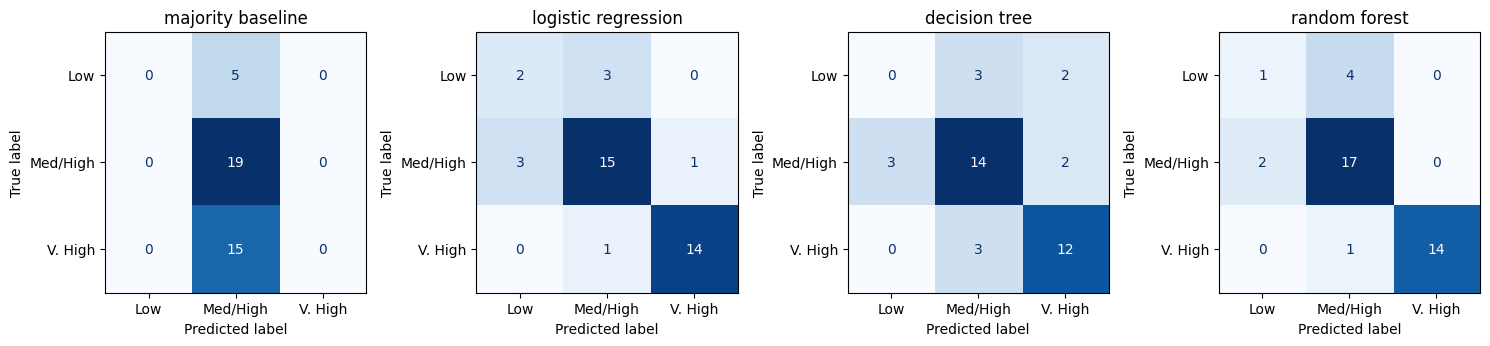

In [9]:
print("=== Logistic regression ===")
print(classification_report(y_test, lr_test_pred, target_names=CLASS_NAMES, zero_division=0))
print("=== Decision tree ===")
print(classification_report(y_test, dt_test_pred, target_names=CLASS_NAMES, zero_division=0))
print("=== Random forest ===")
print(classification_report(y_test, rf_test_pred, target_names=CLASS_NAMES, zero_division=0))

model_names = ["majority baseline", "logistic regression", "decision tree", "random forest"]
test_preds = [baseline_test_pred, lr_test_pred, dt_test_pred, rf_test_pred]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for i in range(4):
    cm = confusion_matrix(y_test, test_preds[i], labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low", "Med/High", "V. High"])
    disp.plot(ax=axes[i], cmap=plt.cm.Blues, colorbar=False)
    axes[i].set_title(model_names[i])
plt.tight_layout()
plt.savefig("../figures/confusion_matrices.png", dpi=150)
plt.show()

On the test set, logistic regression gives the best macro F1 (0.708) and balanced accuracy (0.708). The random forest has the highest accuracy (0.821) and an almost perfect Very High class (F1 0.97), but finds only 1 of the 5 Low countries, against 2 of 5 for logistic regression. The decision tree does not identify any Low country (macro F1 0.497). For every model the Very High class is the easiest and the Low class the hardest. Logistic regression and the random forest only confuse neighbouring classes and never mix up Low and Very High; the decision tree is the only model that predicts two Low countries as Very High. The test scores are lower than the CV scores, which is expected given that the test set contains only 39 countries, 5 of them Low.

## 5. Interpretation

### 5.1 Logistic-regression coefficients

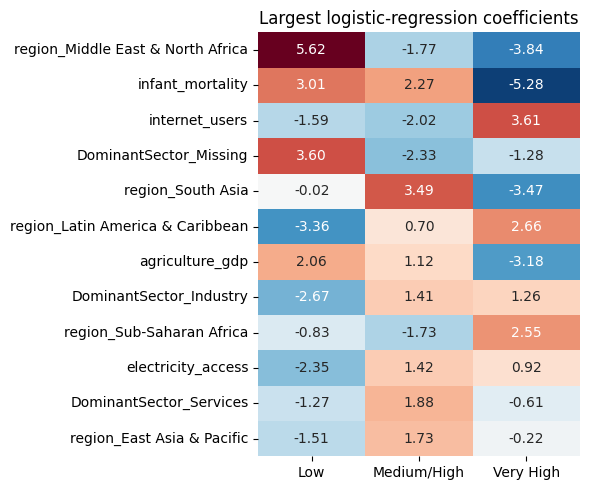

In [10]:
raw_names = lr_model.named_steps["pre"].get_feature_names_out()
feature_names = [name.split("__")[1] for name in raw_names]

coefficients = pd.DataFrame(lr_model.named_steps["clf"].coef_.T,
                            index=feature_names, columns=CLASS_NAMES)

# 12 features with the largest absolute coefficient for any class
largest_weight = coefficients.abs().max(axis=1)
top_features = largest_weight.sort_values(ascending=False).index[:12]

plt.figure(figsize=(6, 5))
sns.heatmap(coefficients.loc[top_features], annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False)
plt.title("Largest logistic-regression coefficients")
plt.tight_layout()
plt.savefig("../figures/logreg_coefficients.png", dpi=150)
plt.show()

Among the numerical indicators, infant mortality has the largest effect: it pushes towards Low (3.01) and strongly away from Very High (−5.28). The agriculture share of GDP shows the same pattern (2.06 for Low, −3.18 for Very High), while internet use pushes towards Very High (3.61) and electricity access away from Low (−2.35). Several categorical columns also receive large weights: the Middle East/North Africa region (5.62 for Low), a missing `DominantSector` (3.60 for Low, i.e. countries with incomplete sector data tend to be Low), and South Asia (3.49 for Medium/High).

These coefficients should be read with caution. With `C = 100` the model is almost unregularised, so the weights are large and sensitive to the few countries in each region or category. The leading indicators are also strongly correlated (e.g. r = 0.84 between internet use and electricity access, r = −0.83 between internet use and infant mortality), so the model can share weight between them in an arbitrary way. Individual coefficients are therefore not stable estimates of each indicator's separate effect.

### 5.2 Random-forest permutation importance

Permutation importance is computed out-of-fold with 5-fold cross-validation on the training and validation data, because the test set (5 Low countries) is too small for stable estimates.

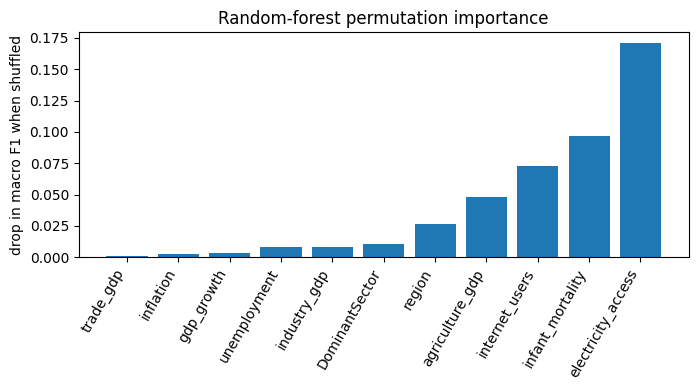

In [11]:
rf_fold_model = Pipeline([
    ("pre", make_preprocessor()),
    ("clf", RandomForestClassifier(n_estimators=300, max_depth=best_rf_depth,
                                   min_samples_leaf=best_rf_leaf, random_state=SEED))
])

fold_importances = []
for fold_idx, (train_idx, val_idx) in enumerate(cv.split(X_trval, y_trval)):
    rf_fold_model.fit(X_trval.iloc[train_idx], y_trval[train_idx])
    result = permutation_importance(rf_fold_model, X_trval.iloc[val_idx], y_trval[val_idx],
                                    scoring="f1_macro", n_repeats=20, random_state=SEED)
    fold_importances.append(result.importances_mean)

importance = pd.Series(np.mean(fold_importances, axis=0), index=X_trval.columns)
importance = importance.sort_values()

plt.figure(figsize=(7, 4))
plt.bar(importance.index, importance.values)
plt.xticks(rotation=60, ha="right")
plt.ylabel("drop in macro F1 when shuffled")
plt.title("Random-forest permutation importance")
plt.tight_layout()
plt.savefig("../figures/permutation_importance.png", dpi=150)
plt.show()

Electricity access is by far the most important feature for the random forest (mean drop in macro F1 of 0.171), followed by infant mortality (0.099), internet use (0.073) and the agriculture share of GDP (0.048). Region has a small effect (0.026), and `DominantSector`, unemployment, industry share, GDP growth, inflation and trade contribute almost nothing (0.010 or less). `DominantSector` adds very little beyond the numerical sector shares it is derived from, which is consistent with this engineered feature being largely redundant. Both models therefore rely mainly on the same group of health and infrastructure indicators, while short-run macroeconomic indicators (growth, inflation, unemployment) carry little information about the HDI category.

### 5.3 Misclassified test countries (random forest)

In [12]:
test_results = pd.DataFrame({
    "country": df.loc[X_test.index, "country"],
    "HDI": df.loc[X_test.index, "hdi"],
    "true class": y_test,
    "predicted class": rf_test_pred
})
class_labels = {0: "Low", 1: "Medium/High", 2: "Very High"}
test_results["true class"] = test_results["true class"].replace(class_labels)
test_results["predicted class"] = test_results["predicted class"].replace(class_labels)

misclassified = test_results[test_results["true class"] != test_results["predicted class"]]
misclassified.sort_values("HDI")

,country,HDI,true class,predicted class
52,Eritrea,0.503,Low,Medium/High
149,Sudan,0.511,Low,Medium/High
45,Djibouti,0.513,Low,Medium/High
65,Gambia,0.524,Low,Medium/High
178,Tanzania (United Republic of),0.555,Medium/High,Low
179,Uganda,0.582,Medium/High,Low
93,Saint Kitts and Nevis,0.840,Very High,Medium/High


Seven test countries are misclassified. Six of them have an HDI between 0.503 and 0.582, close to the 0.550 boundary between Low and Medium/High: Eritrea, Sudan, Djibouti and Gambia are Low but predicted Medium/High, while Tanzania and Uganda are Medium/High but predicted Low. Countries near a class threshold have indicator profiles similar to the neighbouring class, so these errors reflect the arbitrary cut-off rather than a failure of the model. Saint Kitts and Nevis (HDI 0.840) is the only Very High country misclassified.

## 6. Discussion and limitations

**Class imbalance.** Only 26 of the 193 countries are in the Low class (5 in the test set), against 93 Medium/High and 74 Very High. One misclassified Low country changes the Low-class recall by 20 percentage points. For this reason, macro F1 and balanced accuracy were used for model selection and evaluation instead of accuracy, which a model can keep high while ignoring the Low class (the majority baseline already reaches 0.487 accuracy). Class weighting (`class_weight="balanced"`) could improve Low-class recall and is left for future work.

**Small sample size.** With 193 countries, each CV fold contains about 23 countries and the test set only 39. The CV standard deviations of the three models (0.07–0.09) are of the same order as the differences between them, so the ranking of logistic regression and random forest is not reliable, and the test scores carry considerable uncertainty.

**Missingness.** The most incomplete features are trade (11.9 % missing), inflation (7.8 %) and unemployment (7.3 %). Missingness is not random: Low countries have on average 1.12 missing predictors, against 0.48 for Medium/High and 0.22 for Very High. Mean imputation fills these gaps with values typical of the whole sample, which may make poorer countries look more average and contribute to the difficulty of the Low class.

**Indicator-year mismatch.** HDI refers to 2023, but 19 feature values were taken from 2021 or 2022 because no 2023 observation was available (documented in `data/feature_year_used.csv`). These values may not reflect the 2023 situation, especially for volatile indicators such as inflation and trade.

**Association, not causation.** The models show which indicators are associated with HDI categories, not what causes development. For example, high electricity access and low infant mortality are predictive of a Very High HDI, but they are also outcomes of development and are correlated with the income and education components of HDI that were deliberately excluded. The results should not be read as evidence that changing one indicator would change a country's HDI category.